# Developing a machine learning model for predicting length of stay in hospital

In this project, we will develop a machine learning model to predict the length of stay (LOS) for patients in a hospital. The LOS is an important metric for hospital management as it helps in resource allocation and improving patient care.

## Data Collection
We will use a dataset that contains patient information, including demographics, medical history, and hospital stay details. The dataset can be sourced from hospital records or publicly available healthcare datasets.

## Data Preprocessing
1. **Data Cleaning**: Handle missing values, remove duplicates, and correct any inconsistencies in the data.
2. **Feature Engineering**: Create new features that may be relevant for predicting LOS, such as the number of previous hospital visits, severity of illness, and comorbidities.
3. **Encoding Categorical Variables**: Convert categorical variables into numerical format using techniques like one-hot encoding or label encoding.
4. **Feature Scaling**: Normalize or standardize the features to ensure that they are on the same scale, which can improve the performance of certain machine learning algorithms.

## Model Selection
We will experiment with several machine learning algorithms to find the best model for predicting LOS. Some of the algorithms we will consider include:
- Linear Regression
- Decision Trees
- Random Forest 
- Gradient Boosting Machines
- Support Vector Machines

## Model Training and Evaluation
1. **Train-Test Split**: Split the dataset into training and testing sets to evaluate the performance of the model.
2. **Model Training**: Train the selected models on the training data.
3. **Model Evaluation**: Evaluate the models using appropriate metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²) to assess their performance in predicting LOS.
4. **Hyperparameter Tuning**: Use techniques like Grid Search or Random Search to optimize the hyperparameters of the models for better performance.
5. **Cross-Validation**: Implement cross-validation to ensure that the model's performance is consistent across different subsets of the data.## Model Deployment
Once we have selected the best-performing model, we will deploy it in a production environment. This involves:
1. **Model Serialization**: Save the trained model using a format like Pickle or Joblib for later use.




In [196]:
# libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Encoding libraries
import logging
import miceforest as mf
import pickle
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [197]:
daring = pd.read_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/ml_data_encoded.csv")

In [198]:
camonet = pd.read_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/test_data.csv")

In [199]:
data = pd.concat([daring, camonet], axis=0)

In [200]:
pd.set_option('display.max_columns', None)
data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [201]:
data.shape

(2360, 11)

# Length of Hospital Stay

In [202]:
data['length_hosp_stay'].describe()

count    2359.000000
mean       30.827045
std        91.884122
min         0.000000
25%         7.000000
50%        15.000000
75%        29.000000
max      1843.000000
Name: length_hosp_stay, dtype: float64

In [203]:
# Drop rows where length_hosp_stay is still NaN after calculation
data.dropna(subset=['length_hosp_stay'], inplace=True)

# ML dataset

In [204]:
ml_data = data.copy()

In [205]:
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [206]:
ml_data.tail()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
591,27.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,8.0,3.0,10.0
592,20.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,8.0,3.0,3.0
593,24.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,8.0,3.0,6.0
594,2.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,8.0,7.0,8.0
595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0


In [207]:
ml_data.isna().sum()

age                       1
num_infection_sites       1
sex                       1
referral                  1
cormobid_condition        1
antibiotics_prescribed    1
growth1                   1
Resistance                1
name_of_rrh               1
ward                      1
length_hosp_stay          0
dtype: int64

In [208]:
# Shuffle rows and reset the index
ml_data = ml_data.sample(frac=1).reset_index(drop=True)

In [209]:
# Set random seed for reproducibility
SEED = 1 
np.random.seed(SEED)

# Define target percentiles to identify rare cases
low_threshold = np.percentile(ml_data["length_hosp_stay"], 25)  # Lower quartile
high_threshold = np.percentile(ml_data["length_hosp_stay"], 75)  # Upper quartile

# Identify minority samples (e.g., extreme low & high values)
minority_samples = ml_data[(ml_data["length_hosp_stay"] <= low_threshold) | (ml_data["length_hosp_stay"] >= high_threshold)]

# Bootstrap resampling (with replacement) to balance the dataset
bootstrapped_minority = minority_samples.sample(n=len(ml_data), replace=True, random_state=SEED)

# Combine with the original dataset
imputed_data = pd.concat([ml_data, bootstrapped_minority])

# Shuffle the final dataset
imputed_data = imputed_data.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Display the new balanced dataset
print(imputed_data.shape)


(4718, 11)


In [210]:
imputed_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,35.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,17.0
1,63.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,5.0,9.0,8.0
2,24.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,3.0,9.0,31.0
3,15.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,7.0,4.0,3.0
4,48.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,3.0,9.0,3.0


In [211]:
X = imputed_data.drop(columns=['length_hosp_stay'])
y = imputed_data['length_hosp_stay']

In [212]:
y.dtypes

dtype('float64')

In [213]:
X.dtypes

age                       float64
num_infection_sites       float64
sex                       float64
referral                  float64
cormobid_condition        float64
antibiotics_prescribed    float64
growth1                   float64
Resistance                float64
name_of_rrh               float64
ward                      float64
dtype: object

In [214]:
cat_columns = X.select_dtypes(include='object').columns
cat_columns

Index([], dtype='object')

In [215]:
X.head

<bound method NDFrame.head of        age  num_infection_sites  sex  referral  cormobid_condition  \
0     35.0                  2.0  1.0       0.0                 0.0   
1     63.0                  1.0  1.0       0.0                 0.0   
2     24.0                  1.0  1.0       1.0                 0.0   
3     15.0                  1.0  0.0       0.0                 0.0   
4     48.0                  1.0  1.0       1.0                 0.0   
...    ...                  ...  ...       ...                 ...   
4713  20.0                  2.0  0.0       0.0                 1.0   
4714  75.0                  1.0  0.0       0.0                 0.0   
4715  38.0                  1.0  1.0       0.0                 0.0   
4716  23.0                  1.0  0.0       0.0                 0.0   
4717  53.0                  1.0  1.0       0.0                 0.0   

      antibiotics_prescribed  growth1  Resistance  name_of_rrh  ward  
0                        1.0      0.0         0.0         

# Correct datatypes of the different columns

In [216]:
X.dtypes

age                       float64
num_infection_sites       float64
sex                       float64
referral                  float64
cormobid_condition        float64
antibiotics_prescribed    float64
growth1                   float64
Resistance                float64
name_of_rrh               float64
ward                      float64
dtype: object

In [217]:
# Converting object columns 'category'
cols = ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance', 'ward', 'name_of_rrh']
X[cols] = X[cols].astype('category')

In [218]:
train_wards = set(X["ward"].unique())
train_wards

{0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, nan, -1.0}

In [219]:
ml_data = pd.concat([X, y], axis=1)
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,35.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,17.0
1,63.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,5.0,9.0,8.0
2,24.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,3.0,9.0,31.0
3,15.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,7.0,4.0,3.0
4,48.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,3.0,9.0,3.0


In [220]:
ml_data.dtypes

age                        float64
num_infection_sites        float64
sex                       category
referral                  category
cormobid_condition        category
antibiotics_prescribed    category
growth1                   category
Resistance                category
name_of_rrh               category
ward                      category
length_hosp_stay           float64
dtype: object

# Pycaret setup

In [221]:
from pycaret.regression import *

In [222]:
s = setup(data = ml_data, target = 'length_hosp_stay', session_id=123)

,Description,Value
0,Session id,123
1,Target,length_hosp_stay
2,Target type,Regression
3,Original data shape,"(4718, 11)"
4,Transformed data shape,"(4718, 30)"
5,Transformed train set shape,"(3302, 30)"
6,Transformed test set shape,"(1416, 30)"
7,Numeric features,2
8,Categorical features,8
9,Rows with missing values,0.0%


In [223]:
best = compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
catboost,CatBoost Regressor,23.9047,3528.8763,54.5643,0.7586,1.1218,2.5228,0.2710
rf,Random Forest Regressor,18.5014,4067.5870,59.0085,0.7387,0.8702,1.7482,0.1260
et,Extra Trees Regressor,12.8138,4406.6857,61.8976,0.7079,0.7253,1.2130,0.1190
xgboost,Extreme Gradient Boosting,20.1072,4261.8648,61.0265,0.7051,0.9923,2.0159,0.0410
lightgbm,Light Gradient Boosting Machine,36.0232,7671.5645,85.5681,0.4655,1.3135,3.4495,0.2900
knn,K Neighbors Regressor,30.2540,8340.9424,89.5731,0.3883,1.0635,2.4070,0.0240
dt,Decision Tree Regressor,14.9540,8242.0611,82.3421,0.3270,0.8040,1.2532,0.0260
gbr,Gradient Boosting Regressor,36.6983,9818.9582,97.7299,0.2879,1.3461,3.7390,0.0650
br,Bayesian Ridge,39.8866,14474.8551,118.4027,0.0094,1.4394,4.2397,0.0230
lasso,Lasso Regression,39.7454,14519.3122,118.5601,0.0073,1.4605,4.3878,0.1780


# Data codebook

In [224]:
%run -i "Scripts/codebook.py"

Codebook generated successfully!


## Visualisations

In [225]:
%run -i "Scripts/visualizations.py"

Numeric variables: Index(['age', 'num_infection_sites', 'length_hosp_stay'], dtype='object')
Categorical variables: Index(['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed',
       'growth1', 'Resistance', 'name_of_rrh', 'ward'],
      dtype='object')

EDA visualization complete!
Plots saved in: Outputs/EDA_Visualizations


<Figure size 800x550 with 0 Axes>

# Machine Learning model development

In [226]:
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,35.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,17.0
1,63.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,5.0,9.0,8.0
2,24.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,3.0,9.0,31.0
3,15.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,7.0,4.0,3.0
4,48.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,3.0,9.0,3.0


In [227]:
ml_data['length_hosp_stay'].describe()

count    4718.000000
mean       40.113607
std       124.325792
min         0.000000
25%         5.000000
50%        14.000000
75%        39.000000
max      1843.000000
Name: length_hosp_stay, dtype: float64

In [228]:
ml_data.loc[ml_data['length_hosp_stay'] > 60, ['length_hosp_stay']]

,length_hosp_stay
5,145.0
6,156.0
7,350.0
43,83.0
56,739.0
...,...
4700,67.0
4703,78.0
4705,1127.0
4706,67.0


In [229]:
ml_data.drop(ml_data[ml_data['length_hosp_stay'] > 60].index, inplace=True)
ml_data.reset_index(drop=True, inplace=True)

<Axes: xlabel='length_hosp_stay', ylabel='Count'>

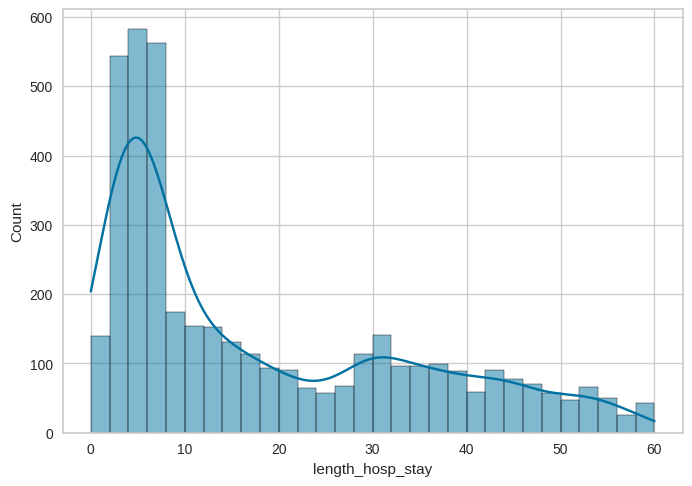

In [230]:
length_of_stay_dist = ml_data['length_hosp_stay']

sns.histplot(length_of_stay_dist, bins=30, kde=True)

<Axes: xlabel='length_hosp_stay', ylabel='Count'>

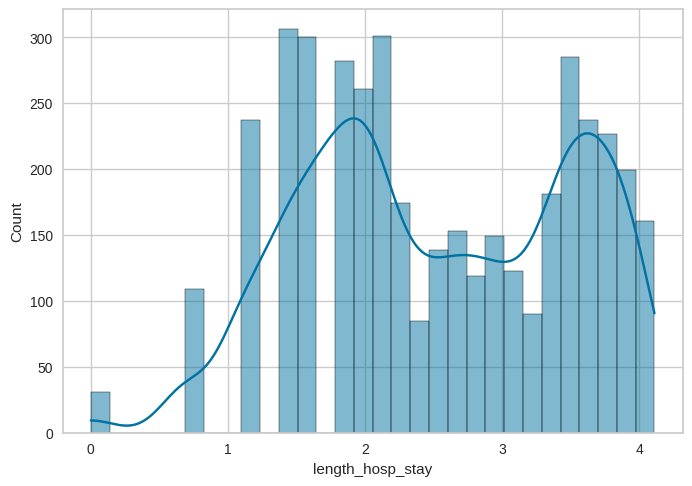

In [231]:
log_length_of_stay_dist = np.log1p(length_of_stay_dist)

sns.histplot(log_length_of_stay_dist, bins=30, kde=True)

RF best params: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 600}
XGB best params: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_child_weight': 5, 'model__n_estimators': 1000, 'model__subsample': 0.8}
LGBM best params: {'model__learning_rate': 0.05, 'model__n_estimators': 800, 'model__num_leaves': 63}
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_RF.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_XGB.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_LGBM.joblib
Saved stacked meta-model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_Stacked_meta.joblib
Saved stacking config: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/stacking_config.joblib

MODEL PERFORMANCE
            RMSE     MAE      R2
RF       10.3220  6.9664  0.5801
XGB      10.8677  7.3134  0.5345
LGBM     

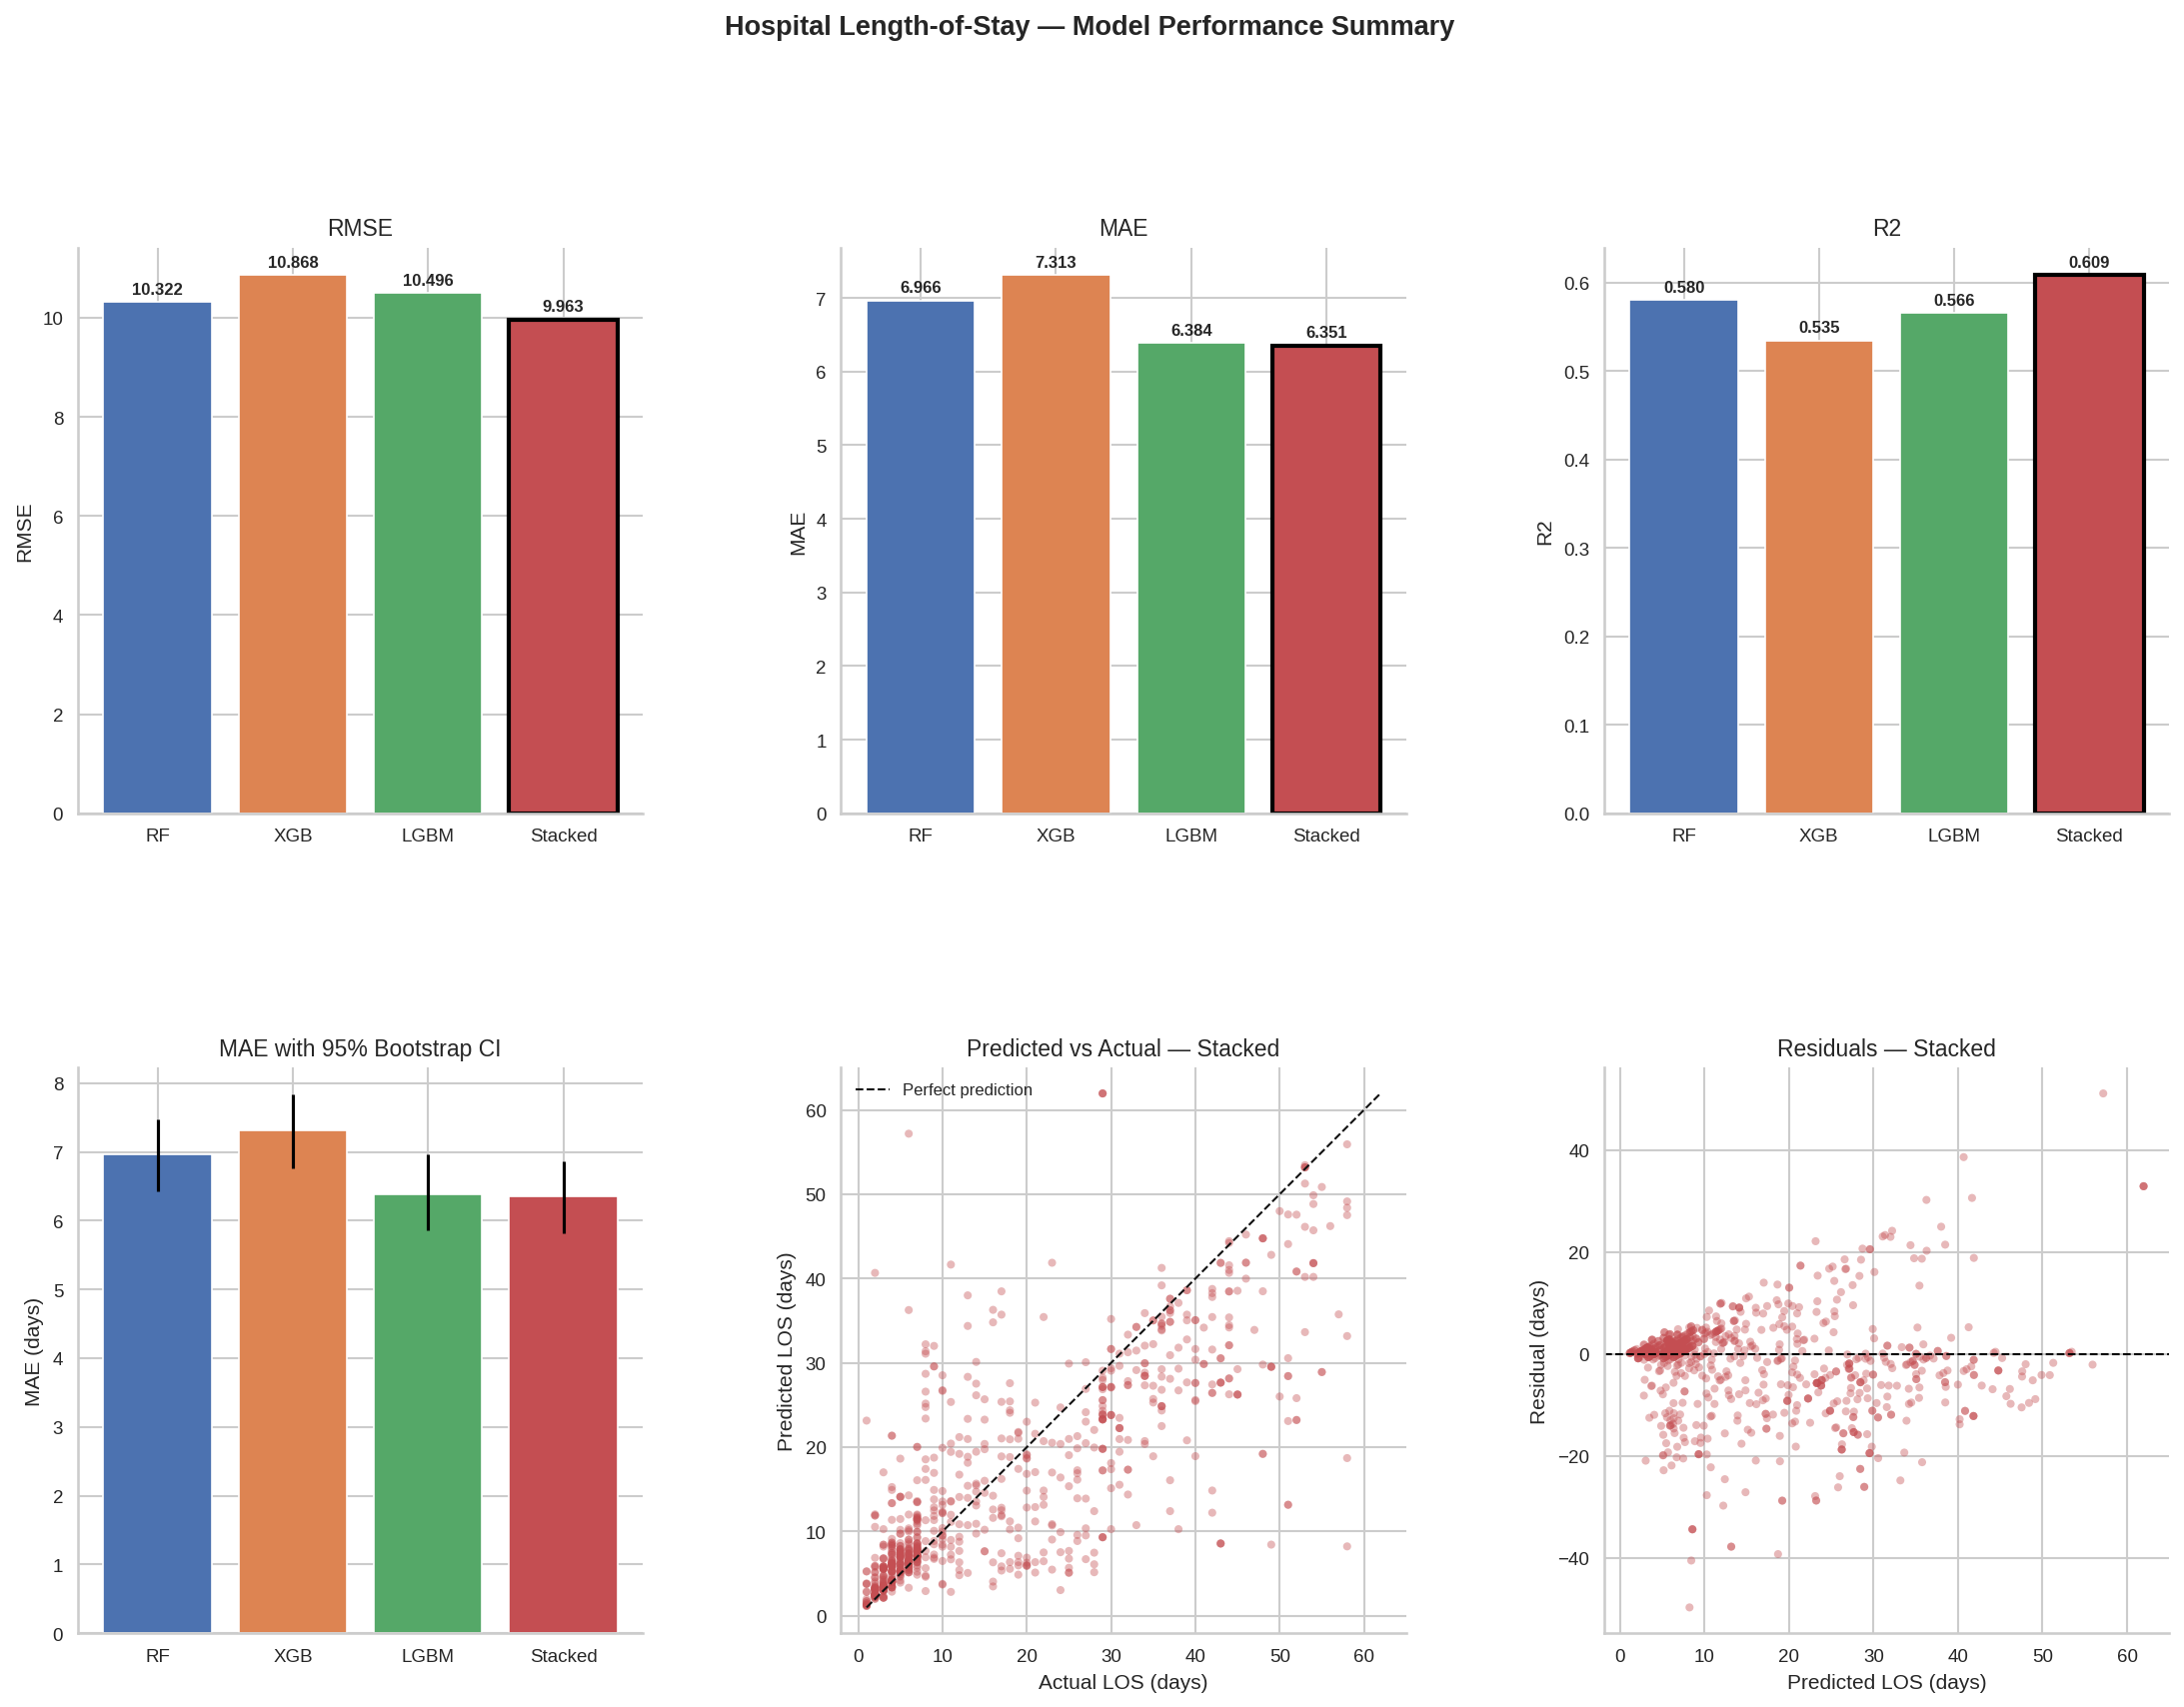

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_performance.png


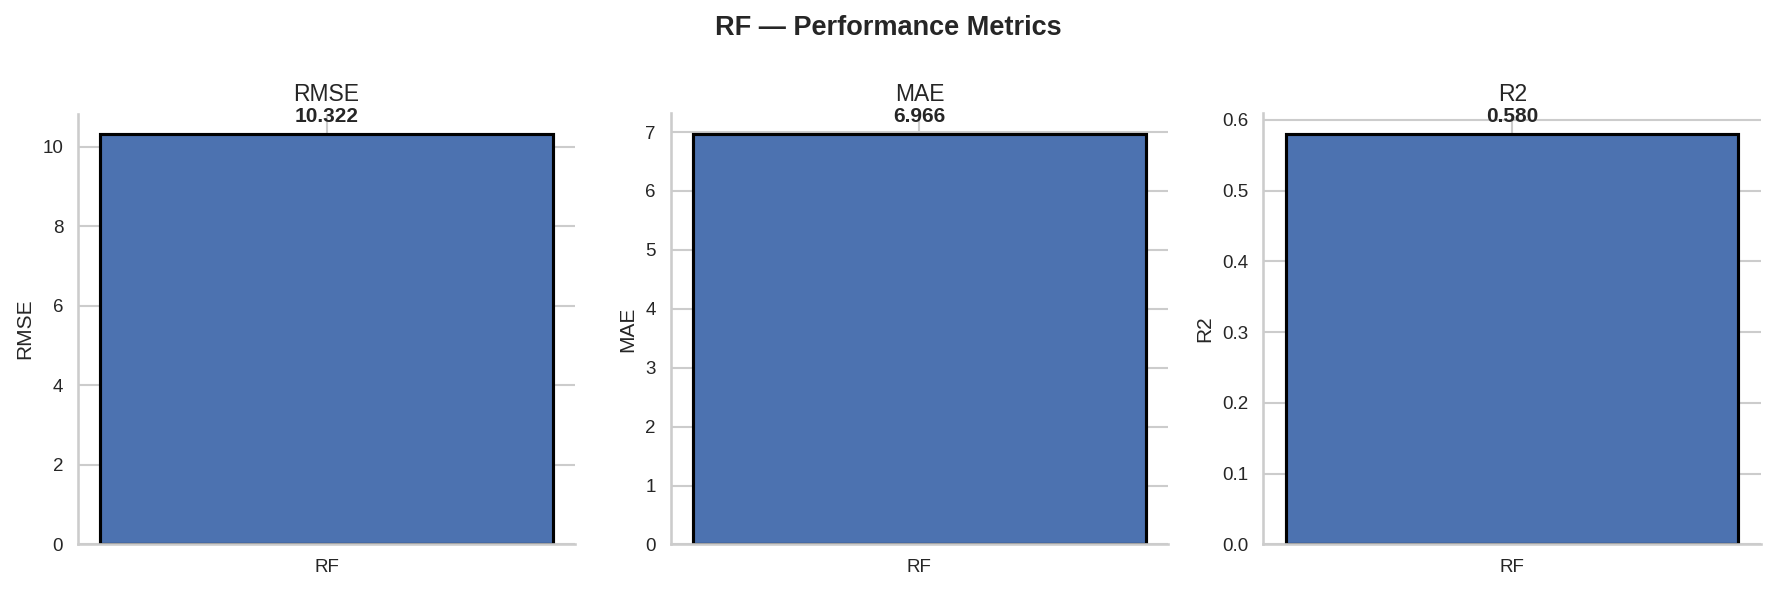

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_RF.png


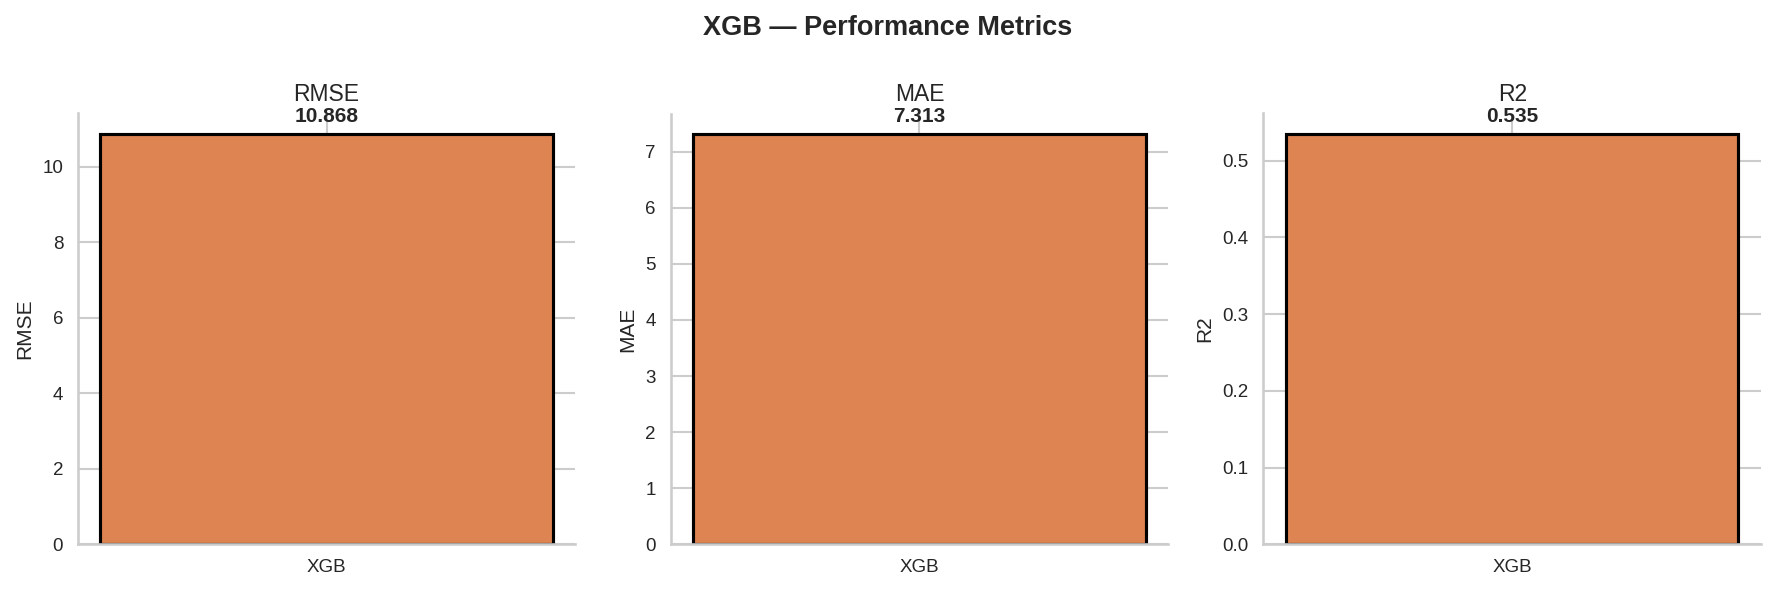

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_XGB.png


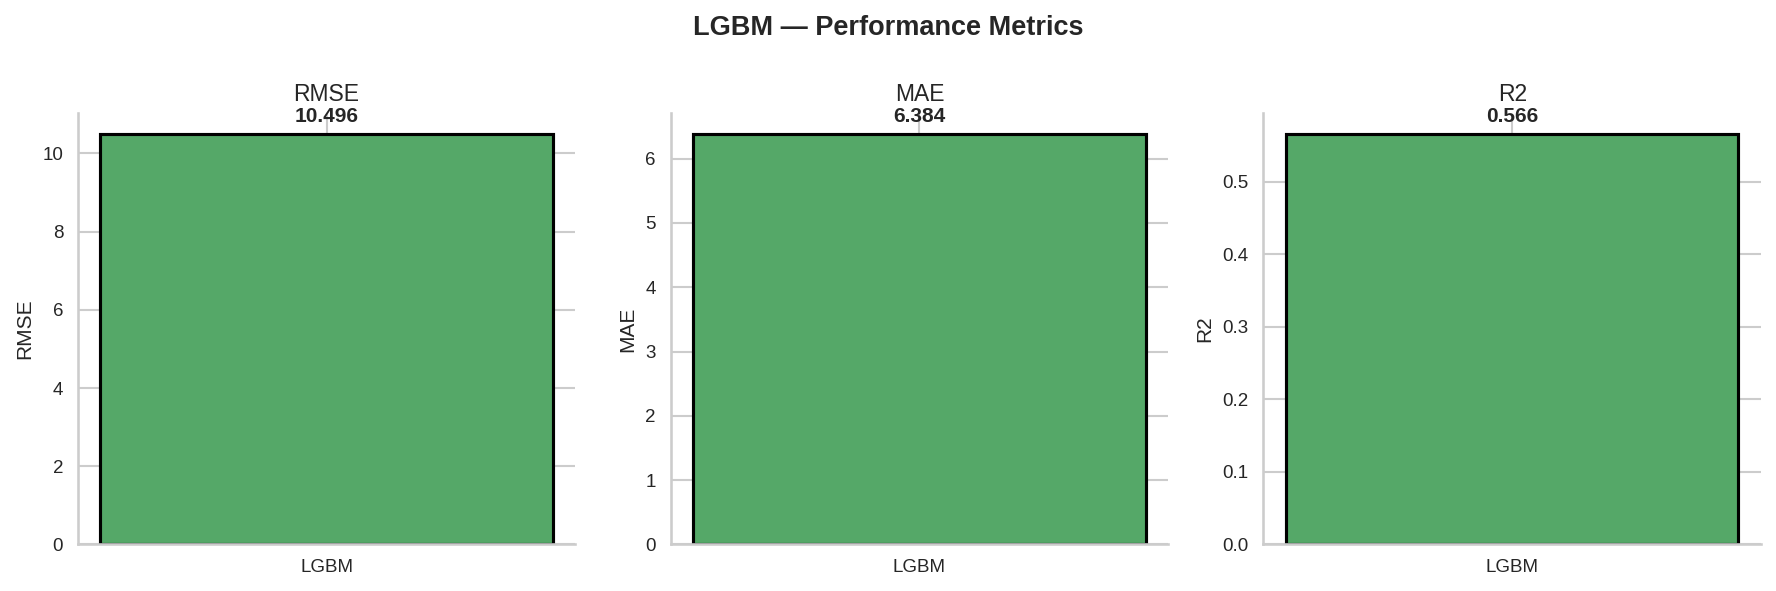

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_LGBM.png


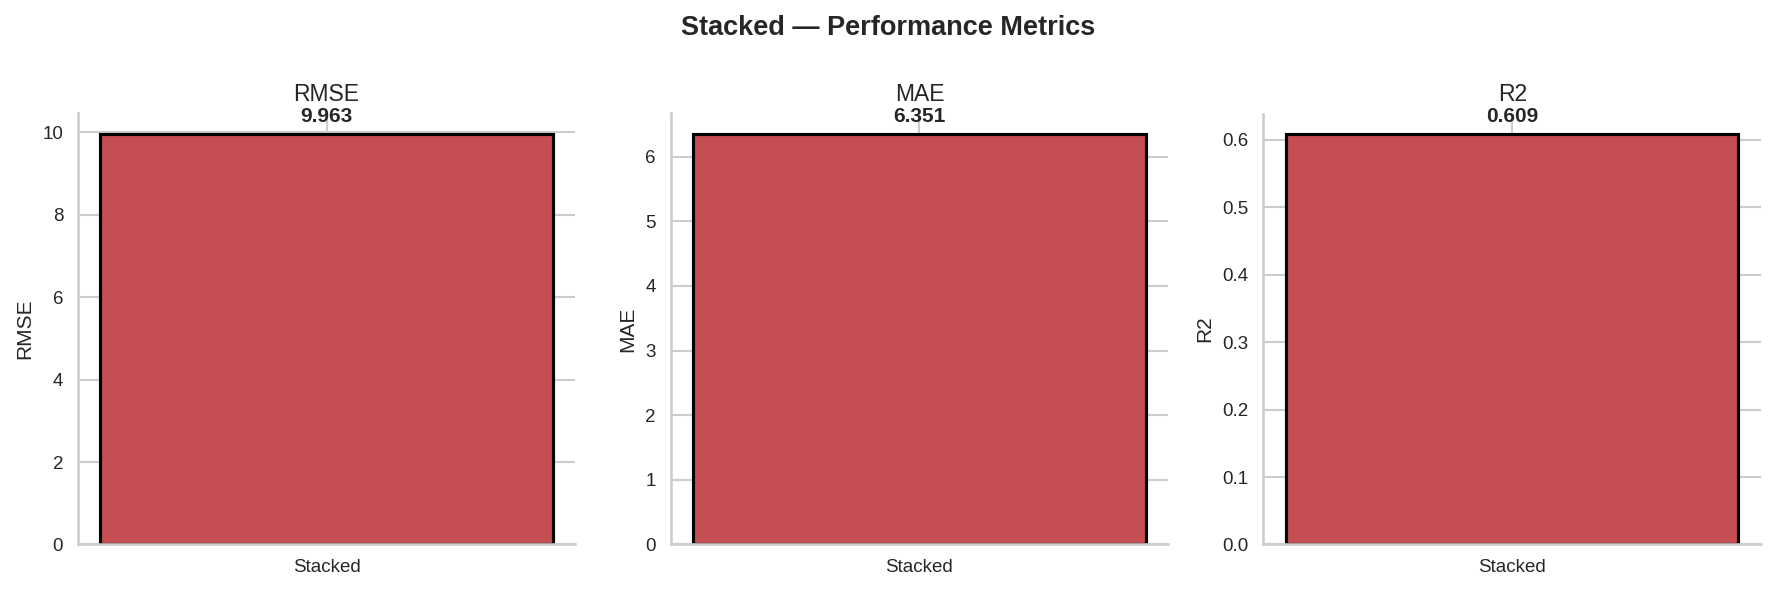

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_Stacked.png


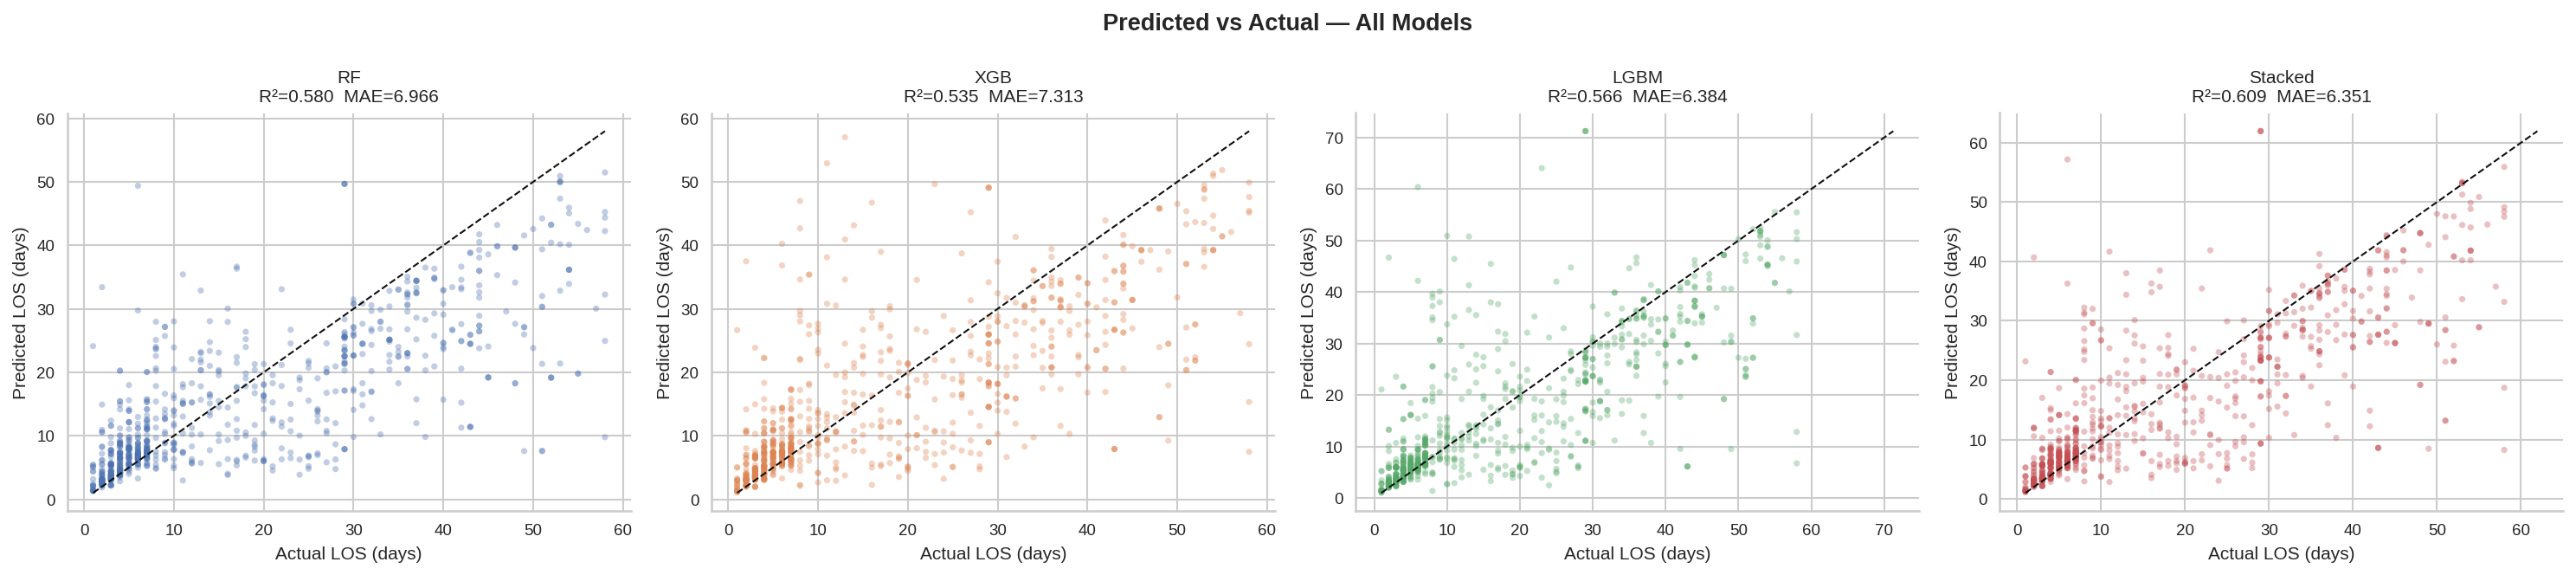

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_all.png


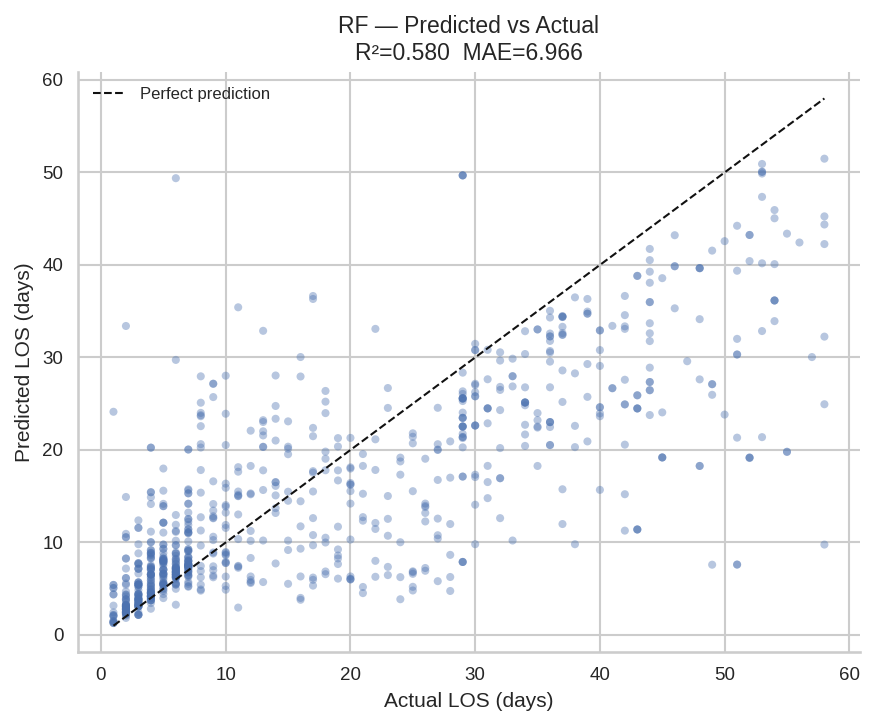

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_RF.png


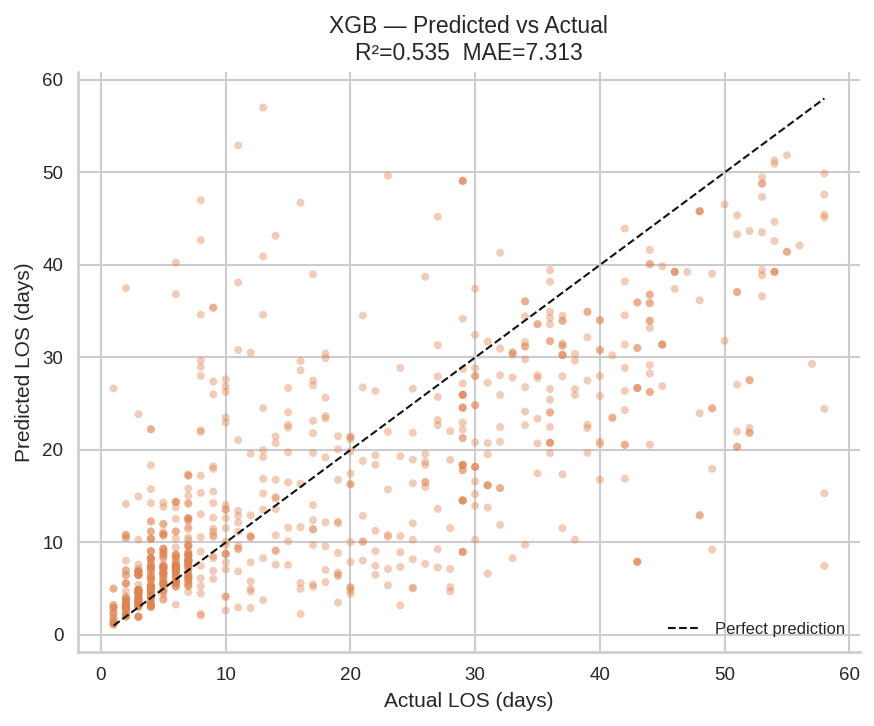

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_XGB.png


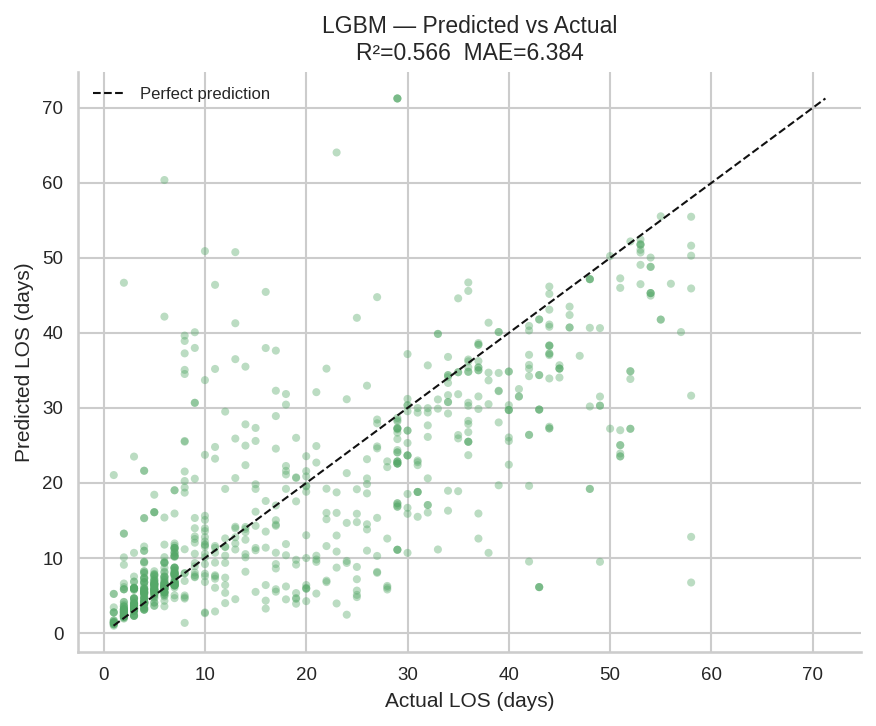

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_LGBM.png


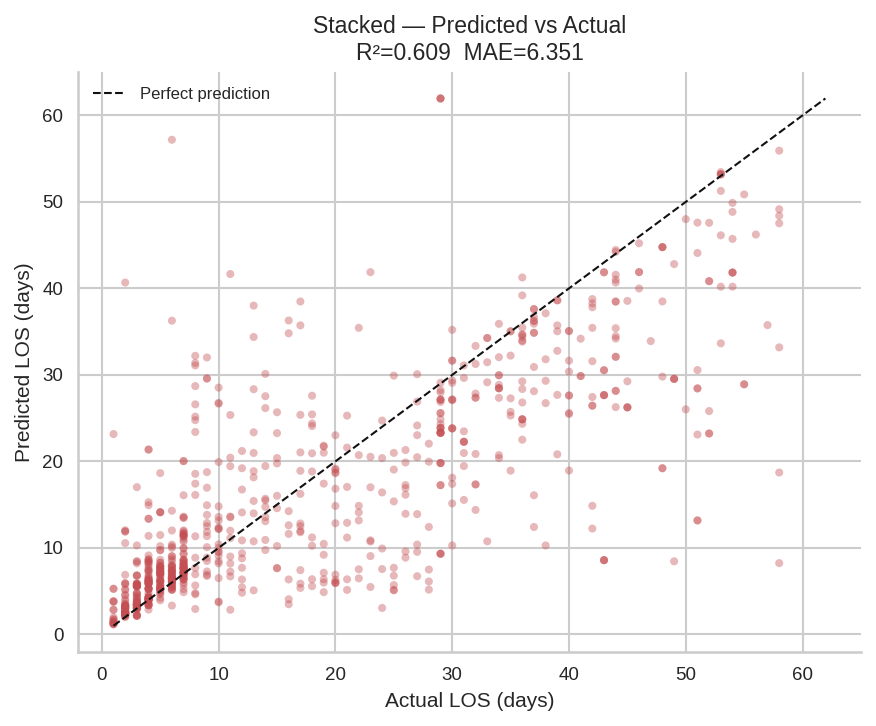

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_Stacked.png


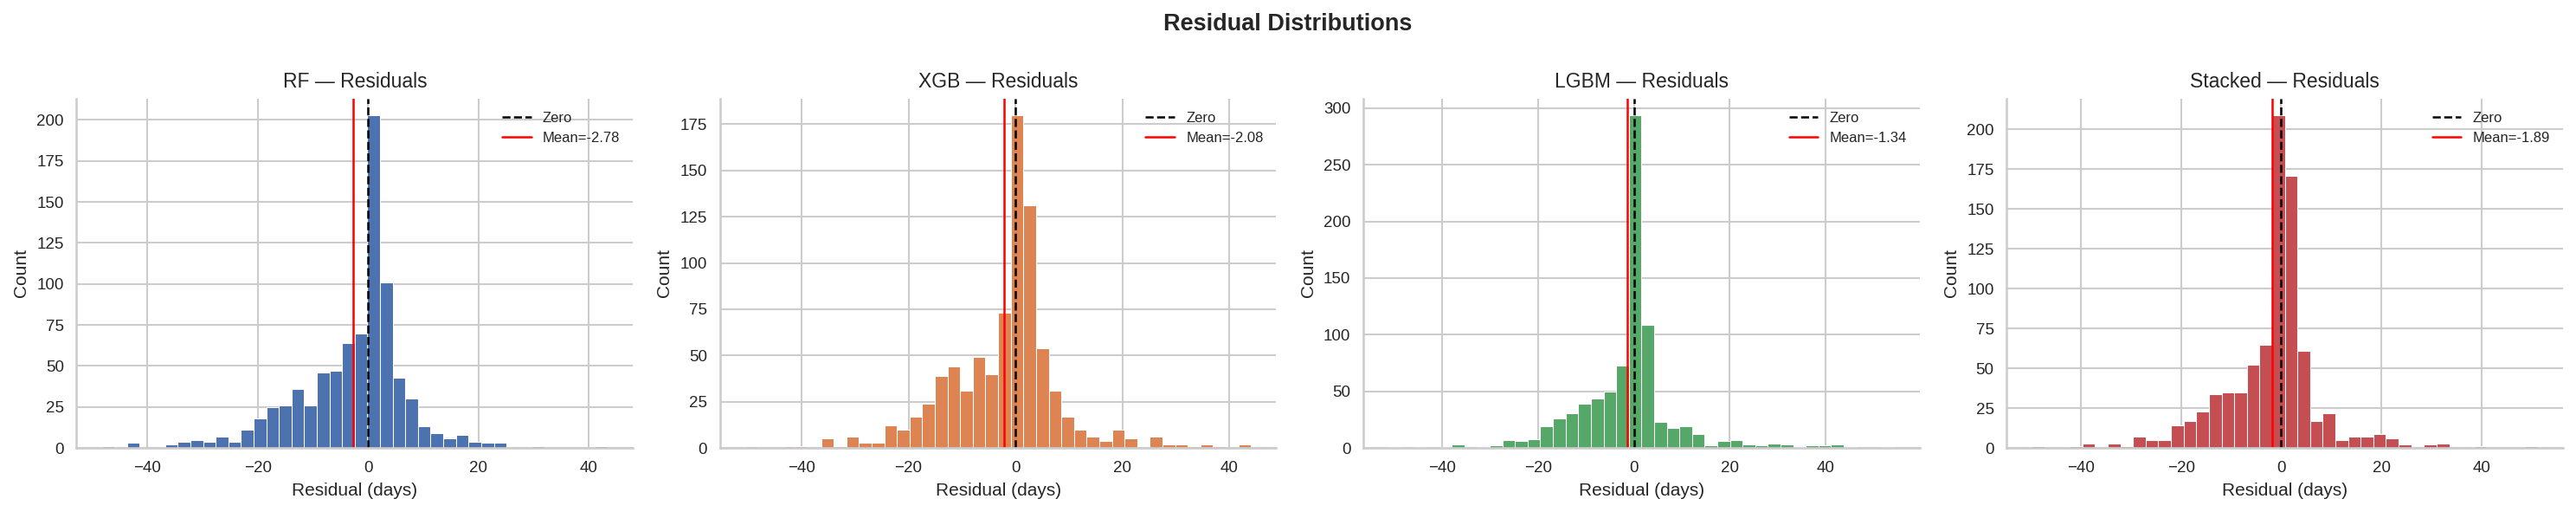

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residual_distributions.png


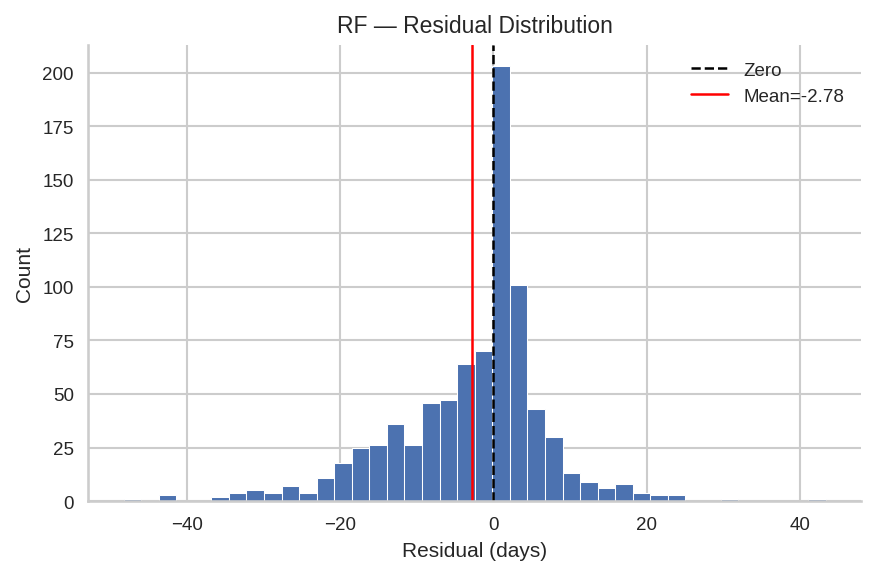

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_RF.png


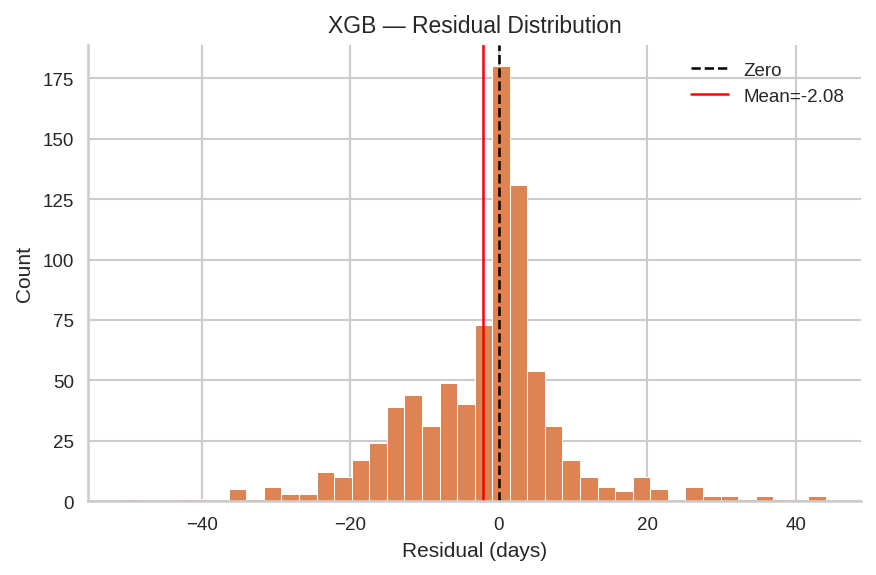

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_XGB.png


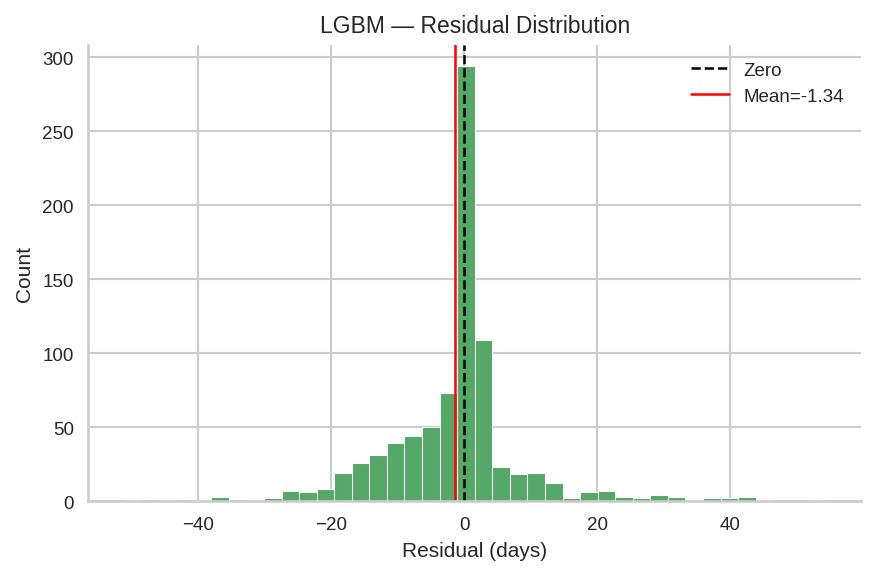

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_LGBM.png


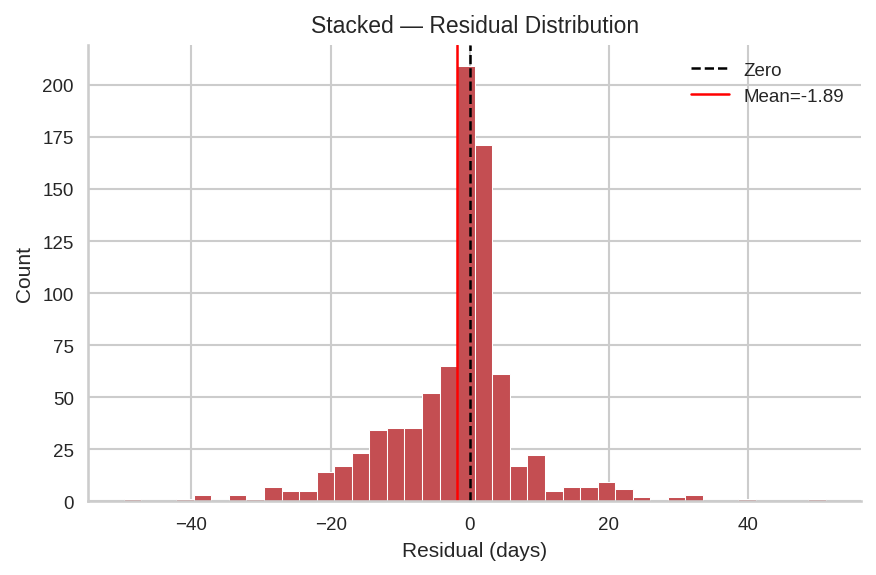

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_Stacked.png


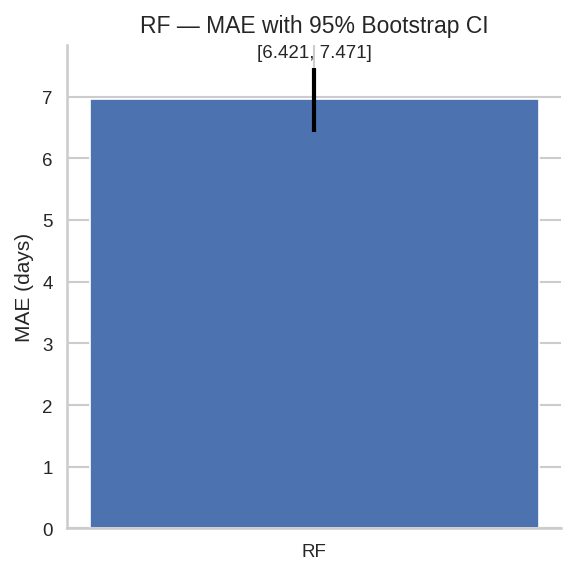

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_RF.png


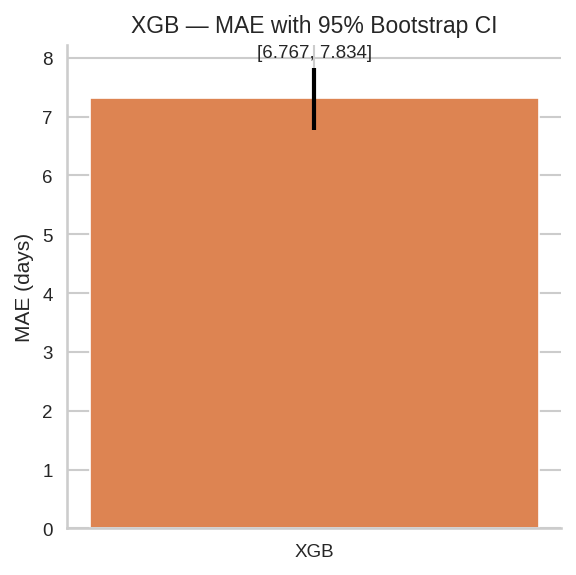

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_XGB.png


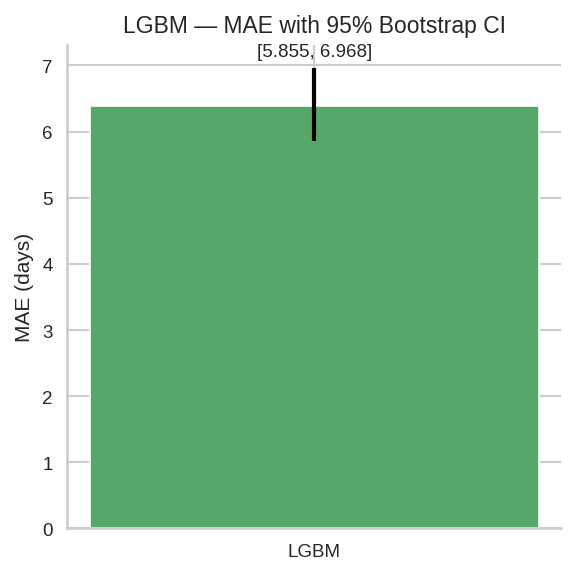

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_LGBM.png


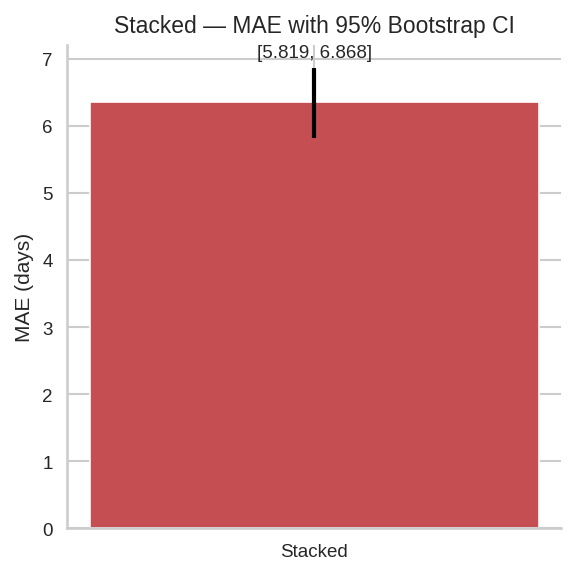

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_Stacked.png


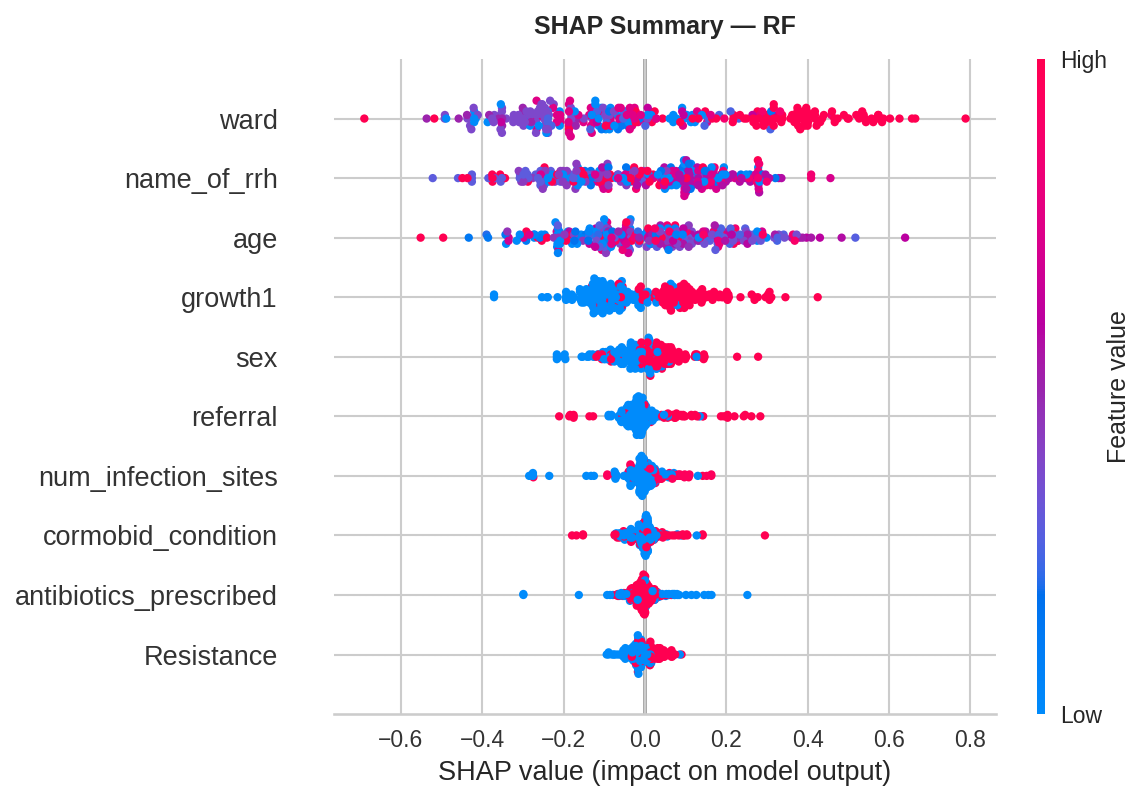

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_RF.png


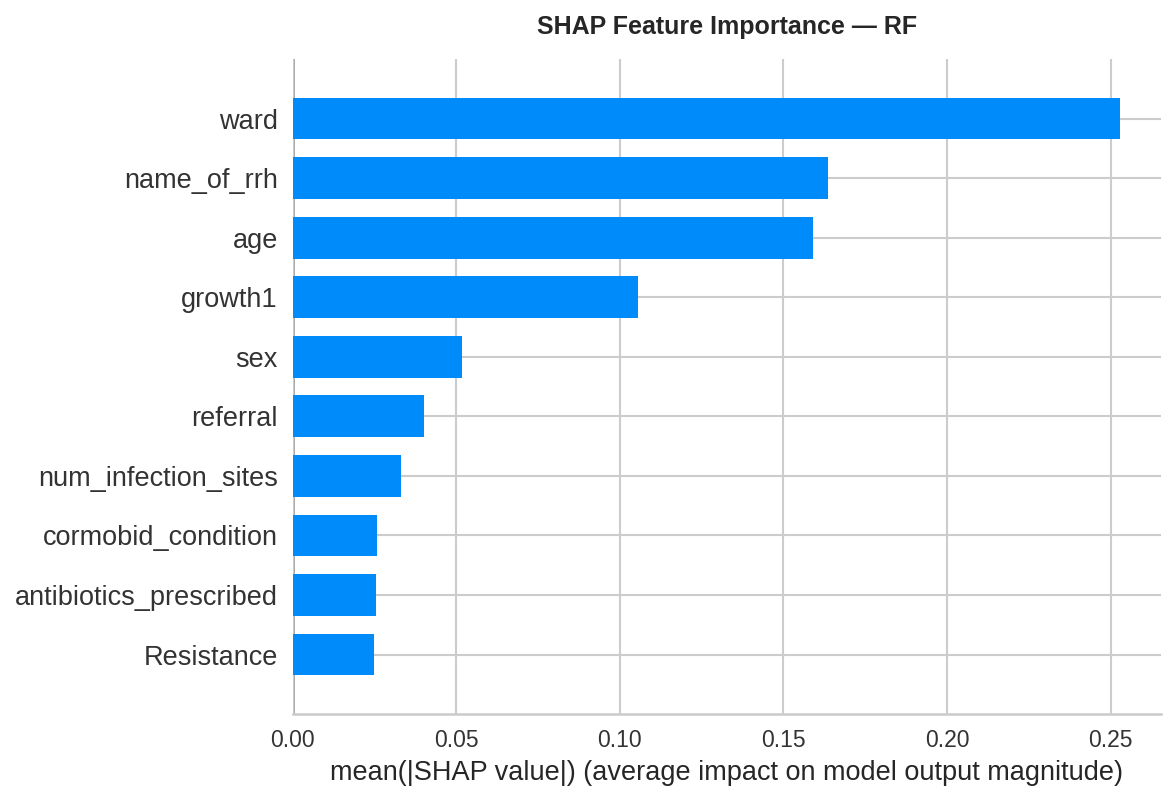

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_RF.png
SHAP failed for XGB: could not convert string to float: '[2.5321465E0]'


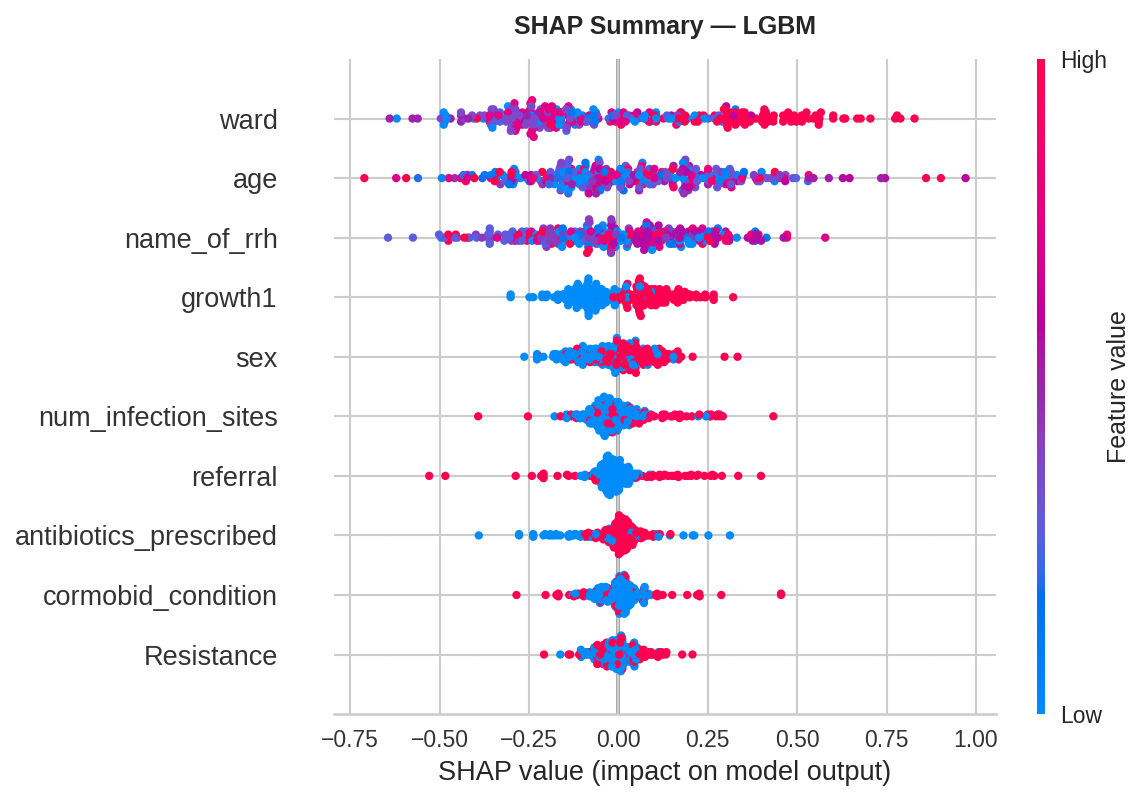

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_LGBM.png


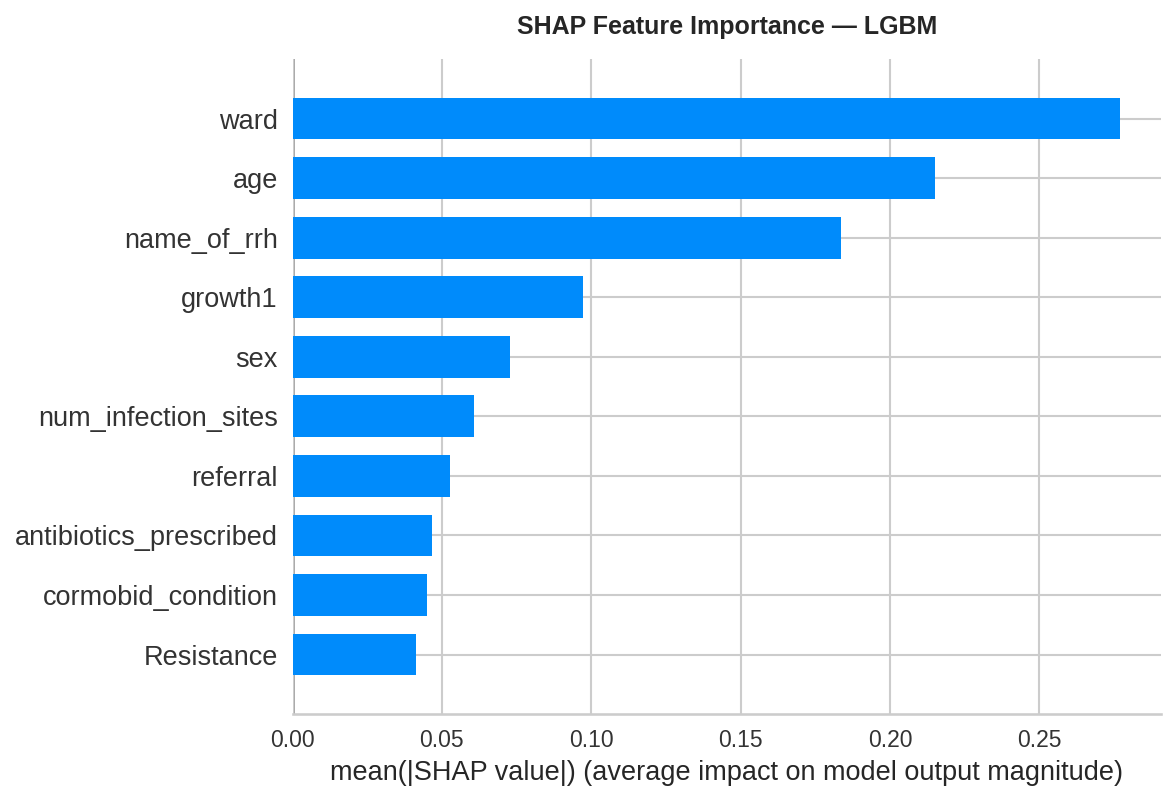

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_LGBM.png

ALL OUTPUTS SAVED TO: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/
  BEST_MODEL.joblib                                       1.1 KB
  BEST_MODEL_info.joblib                                  0.5 KB
  BEST_MODEL_summary.txt                                  0.7 KB
  best_model.joblib                                    4513.8 KB
  best_model_info.joblib                                  0.4 KB
  best_model_summary.txt                                  0.6 KB
  mae_ci_LGBM.png                                        21.2 KB
  mae_ci_RF.png                                          18.9 KB
  mae_ci_Stacked.png                                     22.4 KB
  mae_ci_XGB.png                                         21.5 KB
  metrics_LGBM.png                                       35.3 KB
  metrics_RF.png                                         34.8 KB
  metrics_Stacked.png                               

<Figure size 800x550 with 0 Axes>

In [232]:
# Run the ML pipeline
%run -i "Scripts/machine_learning_pipeline.py"